# release_june_26 — model cross-comparison

Same 3 input frames (sensors) rendered side-by-side under two ridge-regression correction models. Backbone, thresholds, and pre/post-proc are identical across both — only the correction JSON differs, so any bbox/position shift is attributable to the regression variant.

| Column | Emulator output folder | Correction |
| ------ | ---------------------- | ---------- |
| **A** | `output-2026-07-07-19-29-55_int8_regr_b1_10_wb` | `..._wb_alif_box_01_dfl_01_2nd.json` |
| **B** | `output-2026-07-07-19-29-58_int8_regr_b1_10_rq_bg_clahe` | `..._rq_bg_wb_alif_clahe_box_01_dfl_01_2nd.json` |

Backing images are `images/<sensor>.jpg` (320×240) — the same frames the single-frame MP4s in `videos/` were built from.

Prediction schema (from `<stem>_predictions.json`): `bbox = [x, y, w, h]` normalized top-left, `position = [x, y]` normalized keypoint (leg). Only `ts = 0` here (single-frame videos). GT stubs are empty, so all eval metrics are zeros — ignore them; the raw preds are the signal.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

ROOT = Path('.')
IMAGES_DIR = ROOT / 'images'

SENSORS = [
    ('6100002-2000-000008-2550', 'AlgoA — KlymLatest'),
    ('6200001-2000-000008-2550', 'AlgoB — MasterTest'),
    ('6100001-2000-000008-2550', 'AlgoC — KlymLatest_canDriver'),
]

MODELS = [
    ('A · regr_wb_alif',      ROOT / 'output-2026-07-07-19-29-55_int8_regr_b1_10_wb'),
    ('B · regr_rq_bg_clahe',  ROOT / 'output-2026-07-07-19-29-58_int8_regr_b1_10_rq_bg_clahe'),
]

In [2]:
def load_preds(output_dir, sensor, ts=0):
    """Return the `preds` list for the given ts (default 0 — single-frame videos)."""
    data = json.loads((output_dir / f'{sensor}_predictions.json').read_text())
    for frame in data:
        if frame['ts'] == ts:
            return frame['preds']
    return []

# sanity check
for label, mdir in MODELS:
    for sensor, _ in SENSORS:
        preds = load_preds(mdir, sensor)
        confs = [round(p['confidence'], 3) for p in preds]
        print(f'{label:24s} | {sensor[:7]} | {len(preds)} preds  conf={confs}')

A · regr_wb_alif         | 6100002 | 2 preds  conf=[0.27, 0.27]
A · regr_wb_alif         | 6200001 | 2 preds  conf=[0.34, 0.34]
A · regr_wb_alif         | 6100001 | 2 preds  conf=[0.418, 0.418]
B · regr_rq_bg_clahe     | 6100002 | 2 preds  conf=[0.27, 0.27]
B · regr_rq_bg_clahe     | 6200001 | 2 preds  conf=[0.34, 0.34]
B · regr_rq_bg_clahe     | 6100001 | 2 preds  conf=[0.418, 0.418]


In [3]:
def conf_color(conf):
    if conf < 0.5:
        return '#ff3030'
    if conf < 0.7:
        return '#ff9f1c'
    return '#2ecc40'

TYPE_STYLE = {
    'regular':          dict(linestyle='-',  alpha=1.0),
    'filtered_conf':    dict(linestyle='--', alpha=0.55),
    'filtered_novelty': dict(linestyle=':',  alpha=0.55),
}

def draw_preds(ax, img_path, preds, title):
    img = Image.open(img_path).convert('RGB')
    W, H = img.size
    ax.imshow(img)
    ax.set_title(title, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
    for p in preds:
        bx, by, bw, bh = p['bbox']
        px, py = p['position']
        conf = p['confidence']
        c = conf_color(conf)
        style = TYPE_STYLE.get(p.get('detection_type', 'regular'), TYPE_STYLE['regular'])
        ax.add_patch(Rectangle(
            (bx * W, by * H), bw * W, bh * H,
            linewidth=1.6, edgecolor=c, facecolor='none', **style,
        ))
        ax.plot(px * W, py * H, marker='+', color=c, markersize=9, mew=1.6, alpha=style['alpha'])
        ax.text(
            bx * W + 2, max(by * H - 3, 8), f'{conf:.2f}',
            fontsize=7, color='white',
            bbox=dict(facecolor=c, edgecolor='none', pad=1, alpha=0.85),
        )

## Grid — 3 sensors (rows) × 2 model setups (cols)

Boxes are the emulator's post-correction bbox in image coords. `+` = leg keypoint. Label = confidence. Colors: red `<0.5`, orange `<0.7`, green `≥0.7`. Line style: solid = `regular`, dashed = `filtered_conf`, dotted = `filtered_novelty`.

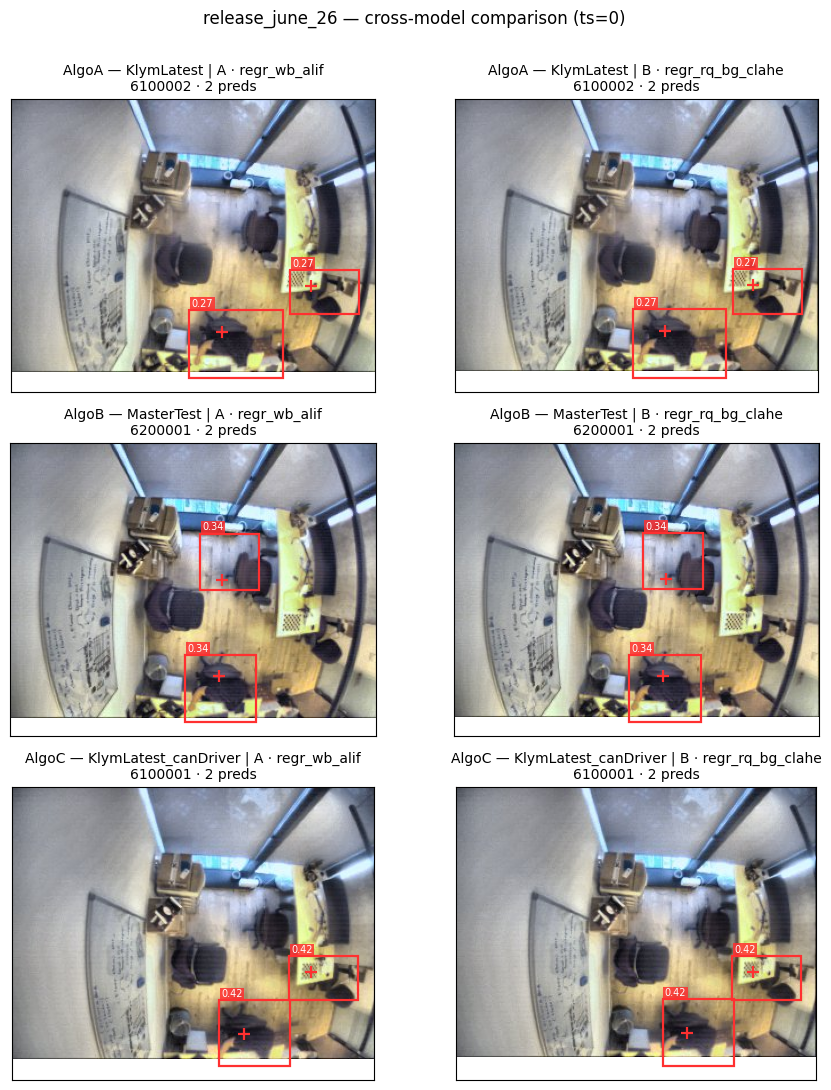

In [4]:
rows, cols = len(SENSORS), len(MODELS)
fig, axes = plt.subplots(rows, cols, figsize=(cols * 4.6, rows * 3.6), squeeze=False)

for r, (sensor, algo_label) in enumerate(SENSORS):
    img_path = IMAGES_DIR / f'{sensor}.jpg'
    for c, (model_label, mdir) in enumerate(MODELS):
        preds = load_preds(mdir, sensor)
        title = f'{algo_label} | {model_label}\n{sensor[:7]} · {len(preds)} preds'
        draw_preds(axes[r][c], img_path, preds, title)

fig.suptitle('release_june_26 — cross-model comparison (ts=0)', fontsize=12, y=1.005)
fig.tight_layout()
plt.show()

## Per-detection delta A → B

Detections are paired between models by their in-list index (both models produce the same count in the same order — same raw backbone output, only the correction differs). Values are pixel deltas (positive = shifted right/down or grew).

If either model ever drops or reorders a detection, indices stop matching — verify with the sanity-check output above before trusting these numbers.

In [5]:
W, H = 320, 240

print(f'{"sensor":8s} {"i":>2s} | {"dx":>6s} {"dy":>6s} {"dw":>6s} {"dh":>6s} | {"dpx":>6s} {"dpy":>6s} | {"dconf":>7s}')
print('-' * 72)
for sensor, _ in SENSORS:
    a = load_preds(MODELS[0][1], sensor)
    b = load_preds(MODELS[1][1], sensor)
    for i, (pa, pb) in enumerate(zip(a, b)):
        dbx = (pb['bbox'][0] - pa['bbox'][0]) * W
        dby = (pb['bbox'][1] - pa['bbox'][1]) * H
        dbw = (pb['bbox'][2] - pa['bbox'][2]) * W
        dbh = (pb['bbox'][3] - pa['bbox'][3]) * H
        dpx = (pb['position'][0] - pa['position'][0]) * W
        dpy = (pb['position'][1] - pa['position'][1]) * H
        dconf = pb['confidence'] - pa['confidence']
        print(f'{sensor[:7]:8s} {i:>2d} | {dbx:>6.2f} {dby:>6.2f} {dbw:>6.2f} {dbh:>6.2f} | {dpx:>6.2f} {dpy:>6.2f} | {dconf:>+7.3f}')

sensor    i |     dx     dy     dw     dh |    dpx    dpy |   dconf
------------------------------------------------------------------------
6100002   0 |   0.37   0.42   0.66   0.35 |  -0.36   0.47 |  +0.000
6100002   1 |   0.42   0.34   0.43   0.62 |   0.24   0.59 |  +0.000
6200001   0 |   0.15   0.11   0.42   0.10 |   0.31  -0.05 |  +0.000
6200001   1 |   0.38   0.34   0.80   0.78 |   0.15   0.63 |  +0.000
6100001   0 |   0.37   0.42   0.66   0.35 |  -0.36   0.47 |  +0.000
6100001   1 |   0.48   0.43   1.13   1.09 |   0.41   0.41 |  +0.000
